In [4]:
import numpy as np
import matplotlib.pyplot as plt
import hdbscan

In [10]:
import matplotlib.pyplot as plt
import hdbscan
import numpy as np

In [11]:
def plot(X, labels, probabilities, param, ax):
    scatter = ax.scatter(
        X[:, 0],
        X[:, 1],
        c=labels,
        cmap='viridis',
        s=30,
        alpha=probabilities
    )

    ax.set_title(f"HDBSCAN - {param}")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

    return scatter

In [22]:
from google.colab import files

uploaded = files.upload()

Saving Mall_Customers (1).csv to Mall_Customers (1) (1).csv


In [23]:
import pandas as pd

nama_file = list(uploaded.keys())[0]

df = pd.read_csv(nama_file)

print("Nama file:", nama_file)
print(df.head())
print(df.info())

Nama file: Mall_Customers (1) (1).csv
   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None


In [24]:
print(df.columns.tolist())
print(df.shape)

['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']
(200, 5)


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import hdbscan

from sklearn.preprocessing import StandardScaler

In [26]:
df = pd.read_csv(nama_file)

print(df.head())
print(df.shape)

   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
(200, 5)


In [27]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

print(X.head())
print(X.shape)

   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40
(200, 2)


In [28]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


In [29]:
PARAM = (
    {"min_cluster_size": 5},
    {"min_cluster_size": 3},
    {"min_cluster_size": 25}
)

{'min_cluster_size': 5}
Jumlah cluster dan noise: (array([-1,  0,  1,  2,  3,  4]), array([37, 32, 10, 21, 12, 88]))
{'min_cluster_size': 3}
Jumlah cluster dan noise: (array([-1,  0,  1,  2,  3,  4,  5,  6,  7,  8,  9]), array([35, 33,  4,  6, 14,  8,  6,  3,  9,  3, 79]))
{'min_cluster_size': 25}
Jumlah cluster dan noise: (array([-1]), array([200]))


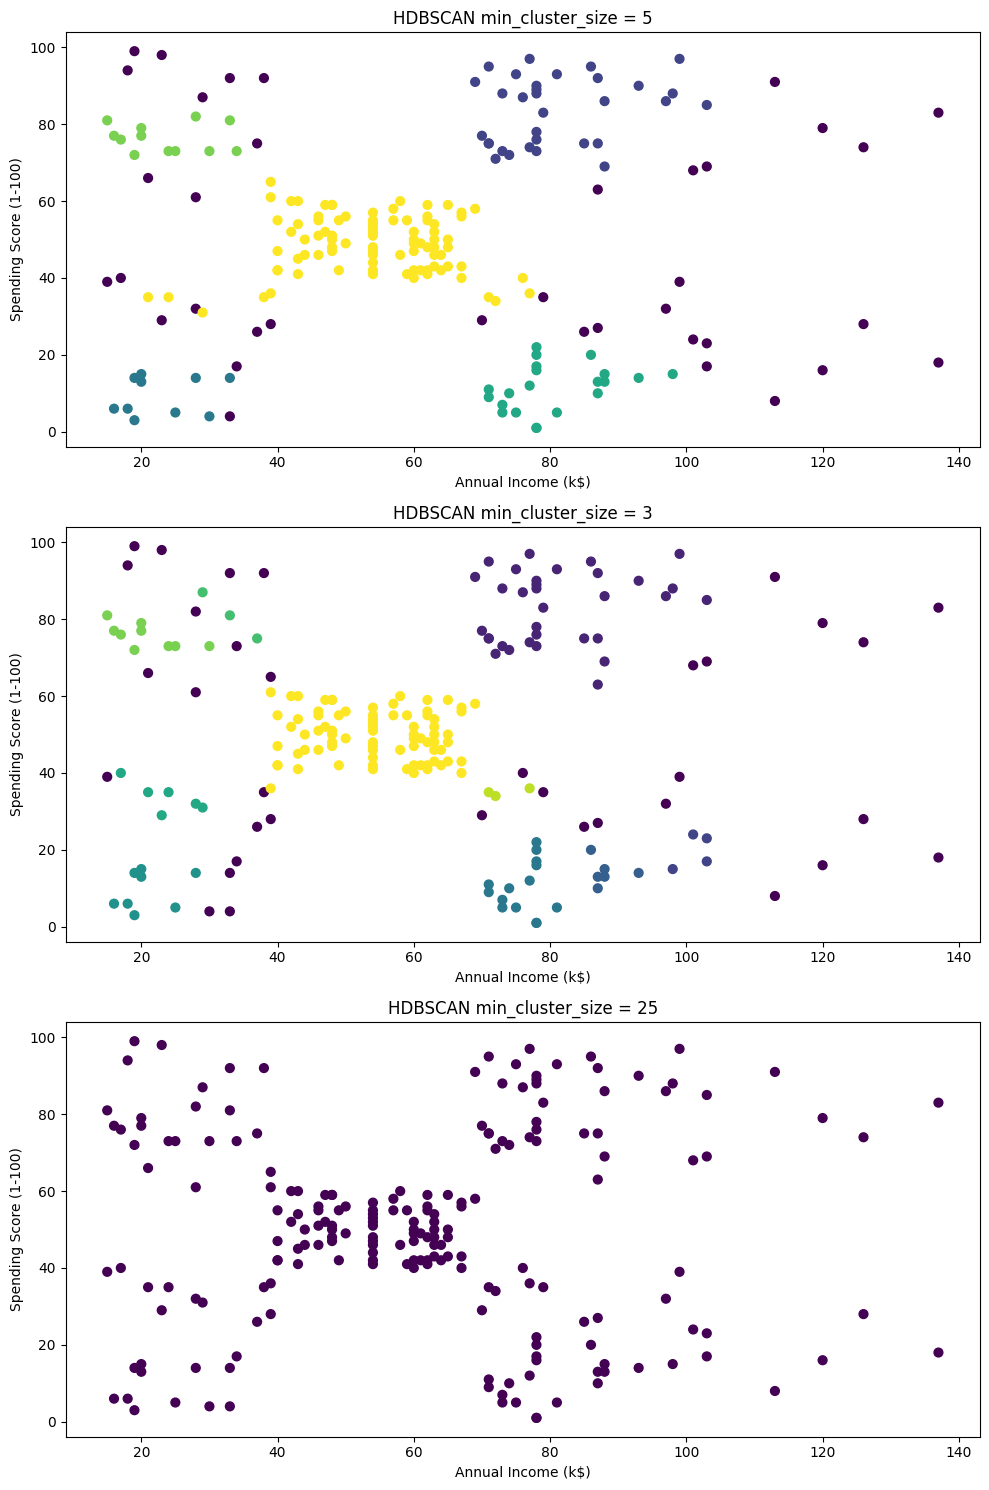

In [30]:
fig, axes = plt.subplots(3, 1, figsize=(10, 15))

for i, param in enumerate(PARAM):

    hdb = hdbscan.HDBSCAN(**param).fit(X_scaled)

    axes[i].scatter(
        X.iloc[:, 0],
        X.iloc[:, 1],
        c=hdb.labels_,
        cmap='viridis',
        s=40
    )

    axes[i].set_title(
        f"HDBSCAN min_cluster_size = {param['min_cluster_size']}"
    )

    axes[i].set_xlabel('Annual Income (k$)')
    axes[i].set_ylabel('Spending Score (1-100)')

    print(param)
    print("Jumlah cluster dan noise:", np.unique(hdb.labels_, return_counts=True))

plt.tight_layout()
plt.show()

InvalidIndexError: (slice(None, None, None), 0)

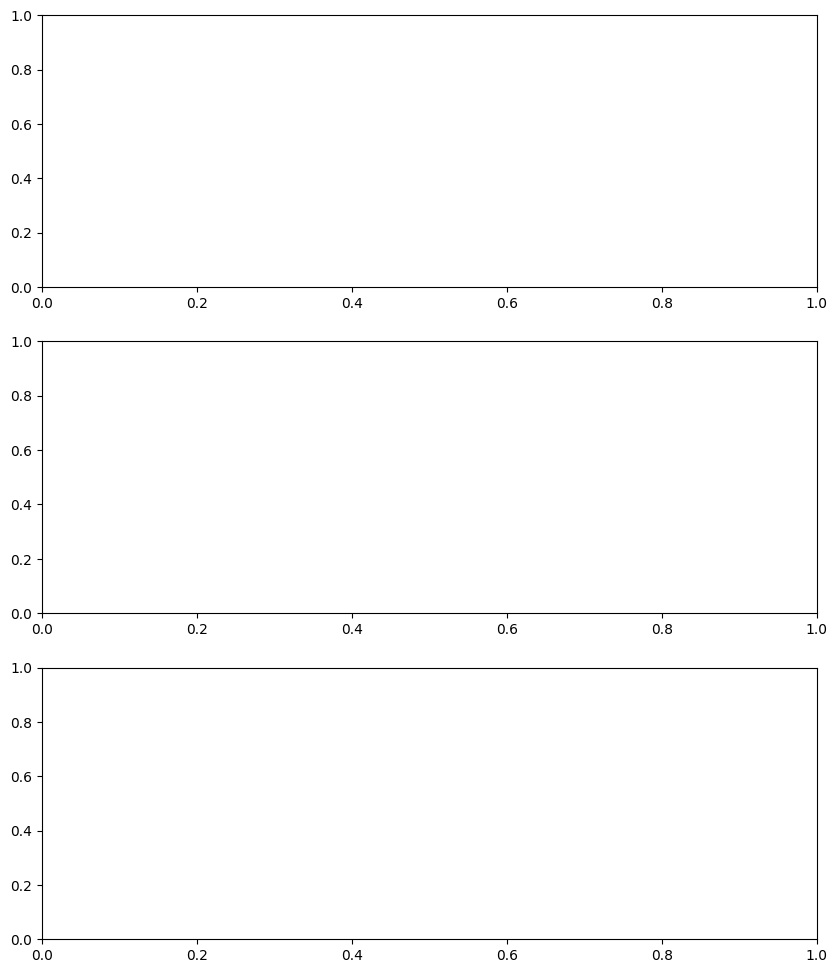

In [31]:
	PARAM = (
	    {"min_cluster_size": 20, "min_samples": 5},
	    {"min_cluster_size": 20, "min_samples": 3},
	    {"min_cluster_size": 20, "min_samples": 25},
	)
	fig, axes = plt.subplots(3, 1, figsize=(10, 12))
	for i, param in enumerate(PARAM):
	    hdb = hdbscan.HDBSCAN(**param).fit(X)
	    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

In [32]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

print(X.shape)
print(X.head())

(200, 2)
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40


Parameter: {'min_cluster_size': 20, 'min_samples': 5}
Hasil cluster: (array([-1,  0,  1,  2]), array([ 41,  32, 106,  21]))
--------------------------------
Parameter: {'min_cluster_size': 20, 'min_samples': 3}
Hasil cluster: (array([-1,  0,  1,  2]), array([ 18,  33,  26, 123]))
--------------------------------
Parameter: {'min_cluster_size': 20, 'min_samples': 25}
Hasil cluster: (array([-1]), array([200]))
--------------------------------


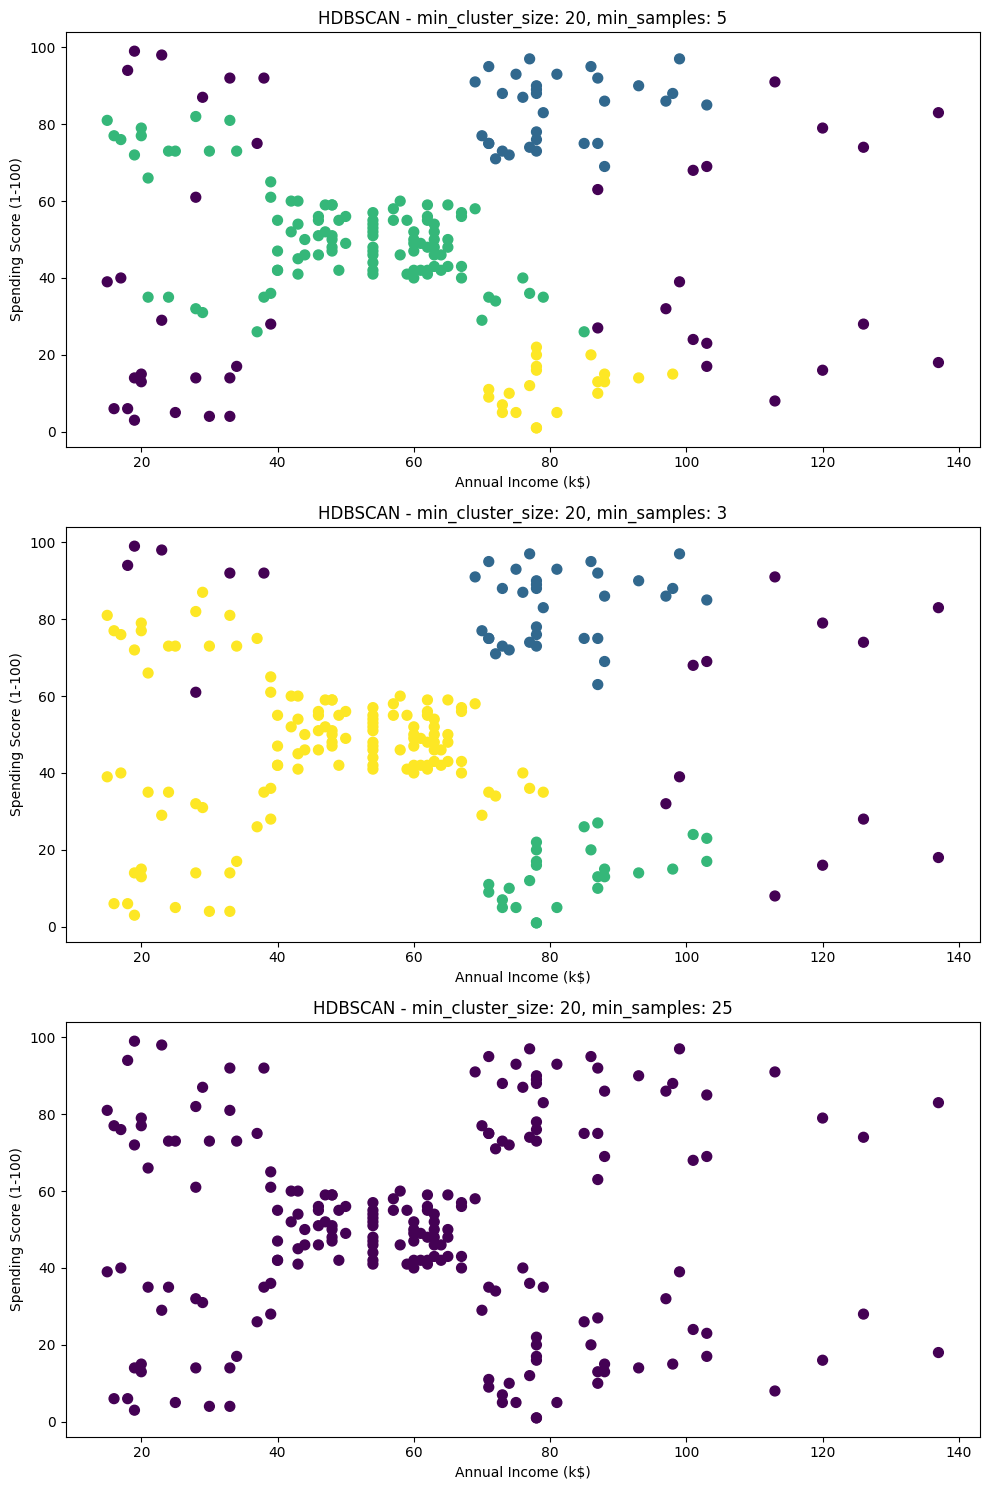

In [33]:
PARAM = (
    {"min_cluster_size": 20, "min_samples": 5},
    {"min_cluster_size": 20, "min_samples": 3},
    {"min_cluster_size": 20, "min_samples": 25}
)

fig, axes = plt.subplots(3, 1, figsize=(10, 15))

for i, param in enumerate(PARAM):

    hdb = hdbscan.HDBSCAN(**param).fit(X)

    axes[i].scatter(
        X.iloc[:, 0],
        X.iloc[:, 1],
        c=hdb.labels_,
        cmap='viridis',
        s=50
    )

    axes[i].set_title(
        f"HDBSCAN - min_cluster_size: {param['min_cluster_size']}, "
        f"min_samples: {param['min_samples']}"
    )

    axes[i].set_xlabel('Annual Income (k$)')
    axes[i].set_ylabel('Spending Score (1-100)')

    print("Parameter:", param)
    print("Hasil cluster:", np.unique(hdb.labels_, return_counts=True))
    print("--------------------------------")

plt.tight_layout()
plt.show()

In [34]:
print("Jumlah baris:", len(X))
print("Jumlah kolom:", X.shape[1])
print("Data kosong:", X.isnull().sum())
print("Tipe data:", X.dtypes)

Jumlah baris: 200
Jumlah kolom: 2
Data kosong: Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
Tipe data: Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object


In [36]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

print(X.shape)

(200, 2)


Cut distance: 0.1
Hasil cluster: (array([-1]), array([200]))
Cut distance: 0.5
Hasil cluster: (array([-1]), array([200]))
Cut distance: 1.0
Hasil cluster: (array([-1]), array([200]))


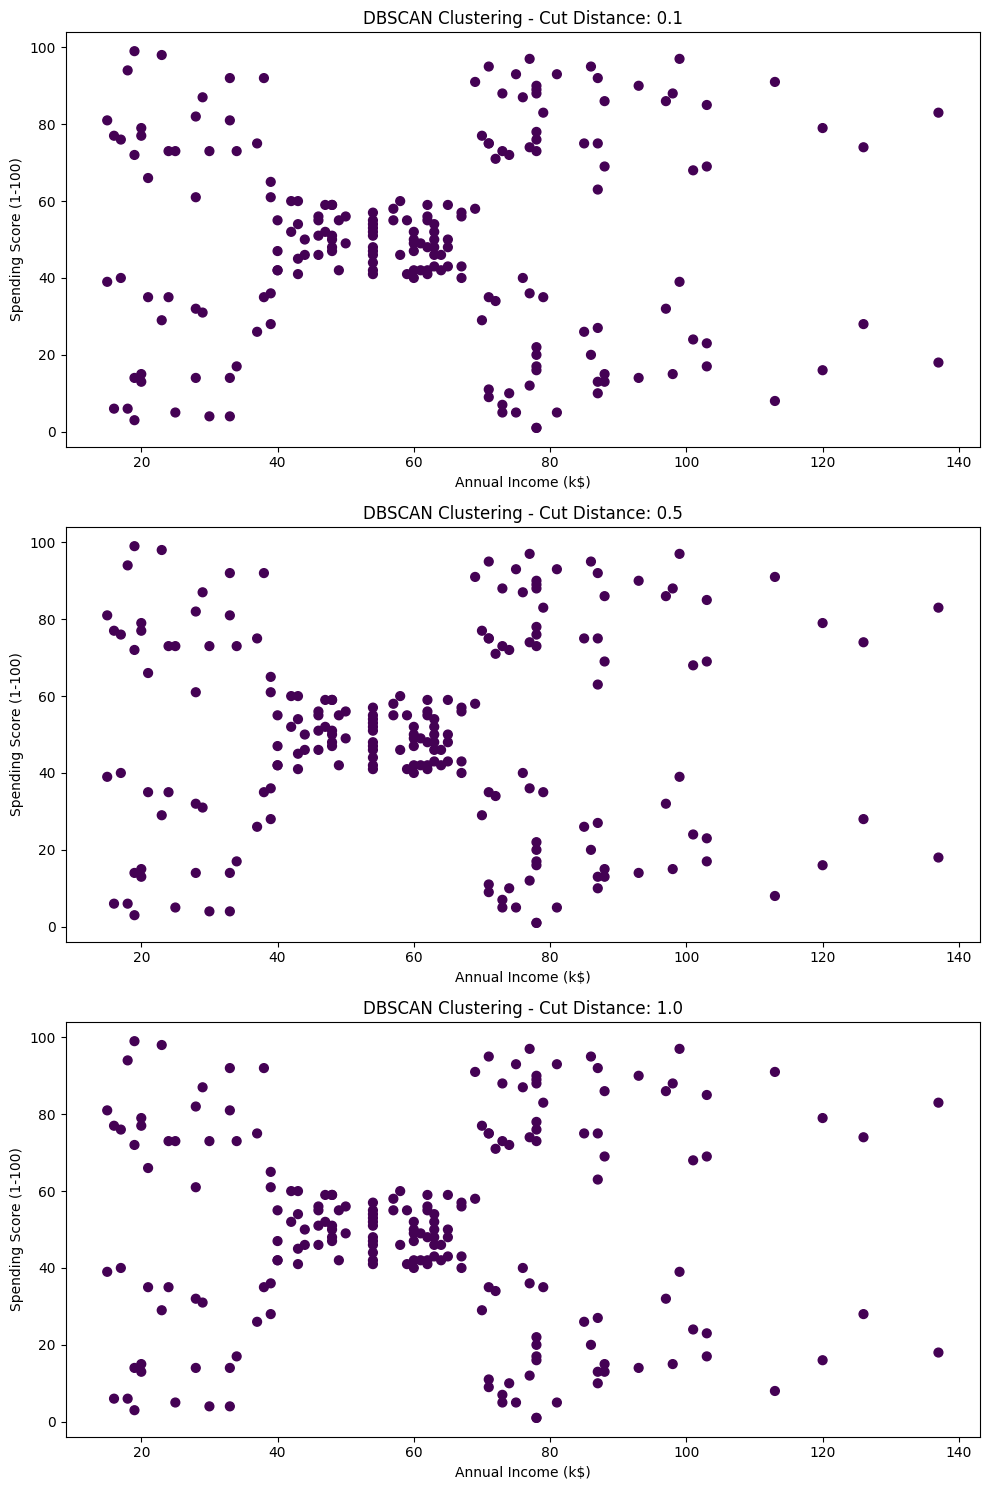

In [37]:
PARAM = (
    {"cut_distance": 0.1},
    {"cut_distance": 0.5},
    {"cut_distance": 1.0}
)

# Fit HDBSCAN
hdb = hdbscan.HDBSCAN(
    min_cluster_size=5,
    gen_min_span_tree=True
).fit(X)

# Membuat subplot
fig, axes = plt.subplots(3, 1, figsize=(10, 15))

for i, param in enumerate(PARAM):

    # DBSCAN clustering
    labels = hdb.dbscan_clustering(
        cut_distance=param["cut_distance"]
    )

    # Visualisasi
    axes[i].scatter(
        X.iloc[:, 0],
        X.iloc[:, 1],
        c=labels,
        cmap='viridis',
        s=40
    )

    axes[i].set_title(
        f"DBSCAN Clustering - Cut Distance: {param['cut_distance']}"
    )

    axes[i].set_xlabel("Annual Income (k$)")
    axes[i].set_ylabel("Spending Score (1-100)")

    print("Cut distance:", param["cut_distance"])
    print("Hasil cluster:", np.unique(labels, return_counts=True))

plt.tight_layout()
plt.show()

In [38]:
	from sklearn.metrics import silhouette_score

	# Compute Silhouette Score for HDBSCAN clustering results
	sil_score = silhouette_score(X, hdb.labels_)
	print(f"Silhouette Score: {sil_score}")

Silhouette Score: 0.3807734971656471


In [39]:
	from sklearn.metrics import davies_bouldin_score

	# Compute Davies-Bouldin Index for HDBSCAN clustering results
	dbi_score = davies_bouldin_score(X, hdb.labels_)
	print(f"Davies-Bouldin Index: {dbi_score}")

Davies-Bouldin Index: 2.106344077874185


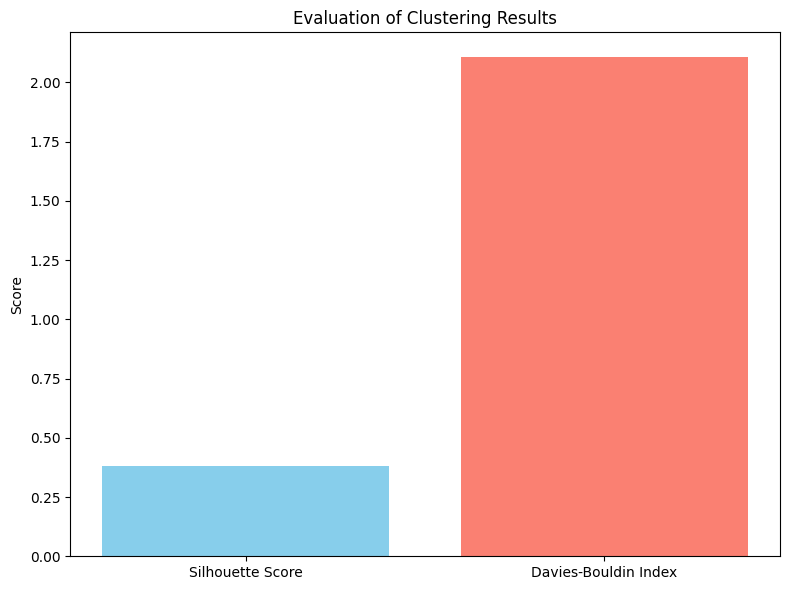

In [40]:
	# For example, if we want to compare DBI and Silhouette Score for several experiments
	scores = {
	    "Silhouette Score": sil_score,
	    "Davies-Bouldin Index": dbi_score
	}

	# Plot the evaluation results
	fig, ax = plt.subplots(figsize=(8, 6))
	ax.bar(scores.keys(), scores.values(), color=['skyblue', 'salmon'])
	ax.set_title("Evaluation of Clustering Results")
	ax.set_ylabel("Score")
	plt.tight_layout()
	plt.show()